# Day 12 · Power — The power in the wind
### #30DayMapChallenge 2026 · ECMWF IFS 9 km open data · Map by Emma Pidduck

The theme is *Power*, so here is where a lot of Europe's electricity increasingly comes from: the
**wind over the North Sea**. This is **wind power density at 100 m** — the height of a modern offshore turbine
hub — the raw energy flowing through each square metre of swept air, right now.

The physics is unforgiving and beautiful: power scales with the **cube** of wind speed. Double the
wind and you get **eight times** the energy. That single fact is why a few metres per second
decides whether an offshore farm is pouring power into the grid or barely turning.

## Method

- Retrieve the **100 m wind components** (`100u`, `100v`) from the ECMWF IFS **9 km (0.1°)**
  open-data forecast.
- Wind speed `V = √(u² + v²)`; **wind power density** `P = ½·ρ·V³`, with standard air density
  `ρ = 1.225 kg/m³`, expressed in kW/m².
- Shade it over the North Sea, mask the land, and mark the big offshore wind farms —
  **Dogger Bank, Hornsea, London Array, Borssele, Gemini, Horns Rev**.

A fixed `ρ` is the convention for wind-resource maps (true density varies a few percent with
temperature and pressure). The real resource is the *long-term* distribution of `V³`; this is one
instantaneous forecast hour — the pattern on the day, not the climatology.

## Licence & attribution

**ECMWF Open Data** is published under **Creative Commons CC-BY-4.0**.

> © ECMWF · source www.ecmwf.int ·
> [Terms of use](https://apps.ecmwf.int/datasets/licences/general/).

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve 100 m wind (IFS 9 km) |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read the GRIB into xarray |
| `numpy` · `cartopy` · `matplotlib` | power density, projection, render |

No account needed.

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data cartopy matplotlib

In [2]:
import os, warnings
import numpy as np
import xarray as xr
import earthkit.data as ekd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, to_rgba
import cartopy.crs as ccrs
import cartopy.feature as cfeature
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT = "#ffffff", "#1a2420", "#6b7580"

### Configuration

`RHO` is the standard-atmosphere air density used for wind-resource maps. The major North Sea
offshore wind farms are listed with a label offset so names don't collide.

In [3]:
GRIB = "data/day12_100wind.grib2"
RHO  = 1.225                       # standard air density, kg/m³
EXTENT = [-11, 14, 48, 61]         # W, E, S, N
# name, lat, lon, label offset (pts), horizontal align
FARMS = [
    ("Dogger Bank", 54.75, 2.5,  (7, 4),    "left"),
    ("Hornsea",     53.88, 1.8,  (7, 4),    "left"),
    ("London Array",51.62, 1.5,  (-8, -13), "right"),
    ("Borssele",    51.70, 3.05, (7, 5),    "left"),
    ("Gemini",      54.03, 5.96, (7, 4),    "left"),
    ("Horns Rev",   55.5,  7.8,  (7, 4),    "left")]

## Retrieve — IFS 9 km 100 m wind

`resol="0p1"` gets the 9 km grid (the client defaults to 0.25°).

In [4]:
os.makedirs("data", exist_ok=True)
if not os.path.exists(GRIB):
    from ecmwf.opendata import Client
    Client().retrieve(type="fc", step=0, param=["100u", "100v"], resol="0p1", target=GRIB)

## Read, crop, and compute power density

In [5]:
ds = ekd.from_source("file", GRIB).to_xarray()
# crop to NW Europe up front — the GRIB is global 9 km; working the whole array is needless
ds = ds.sel(longitude=slice(EXTENT[0]-3, EXTENT[1]+4), latitude=slice(EXTENT[3]+2, EXTENT[2]-2))
u, v = ds["100u"], ds["100v"]
lon, lat = u["longitude"].values, u["latitude"].values
when = str(xr.open_dataset(GRIB, engine="cfgrib").valid_time.values)[:16].replace("T", " ") + " UTC"

V = np.sqrt(u.values**2 + v.values**2)      # 100 m wind speed, m/s
P = 0.5 * RHO * V**3 / 1000.0               # wind power density, kW/m²
print(f"{when}   V100 to {V.max():.1f} m/s   power {P.min():.2f} to {P.max():.2f} kW/m²   median {np.median(P):.2f}")

Ignoring index file 'data/day12_100wind.grib2.5b7b6.idx' incompatible with GRIB file


2026-10-29 00:00 UTC   V100 to 19.3 m/s   power 0.00 to 4.42 kW/m²   median 0.26


### Colour — an energy ramp, colourblind-safe

Pale (calm) → green → deep teal (powerful). **Monotonic in luminance** (verified), so the resource
reads by brightness for every colour-vision type, and stays on the house white background.

In [6]:
CMAP = LinearSegmentedColormap.from_list("power", [
    "#fdfdf4", "#e8f0c2", "#bfe0a0", "#84c98a", "#49ac84", "#1f8a7a", "#166a6a", "#123d4a"])
rgb = np.array([to_rgba(CMAP(t))[:3] for t in np.linspace(0, 1, 256)])
lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]
mono = (np.diff(lum) <= 1e-3).all() or (np.diff(lum) >= -1e-3).all()
print("power ramp luminance-monotonic:", bool(mono), f"({lum[0]:.2f} -> {lum[-1]:.2f})")

power ramp luminance-monotonic: True (0.99 -> 0.21)


## Render

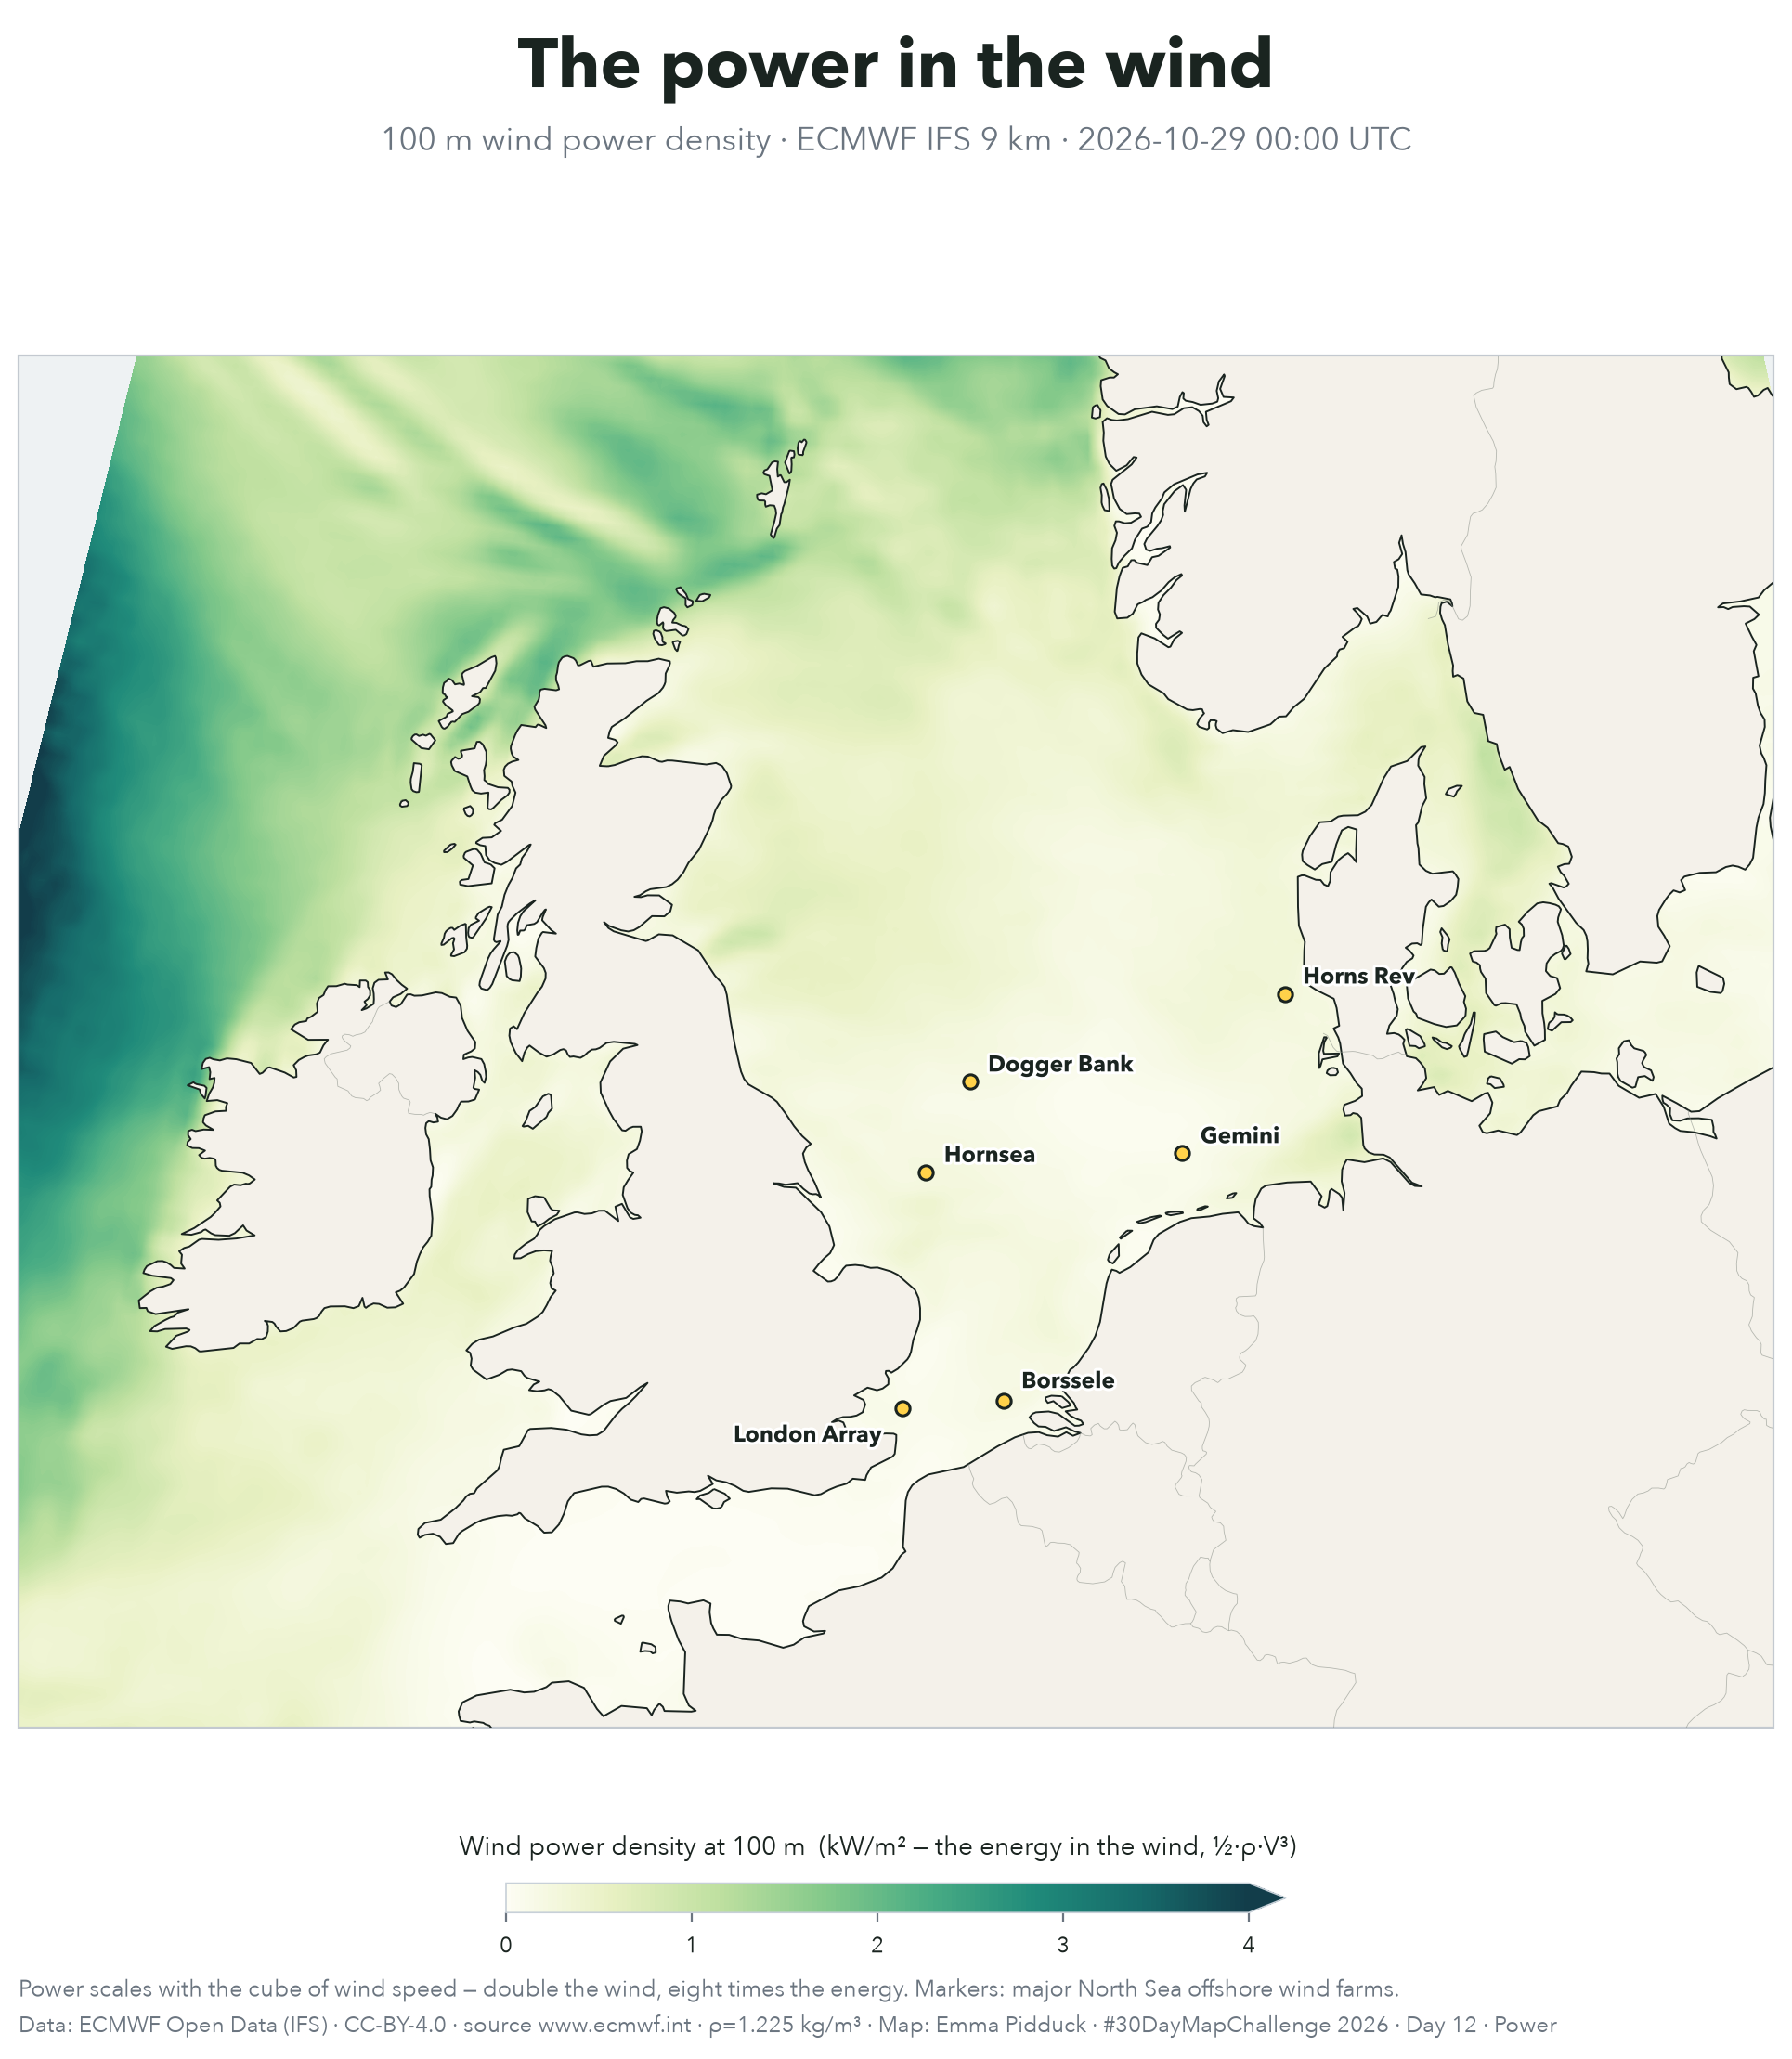

In [7]:
proj = ccrs.LambertConformal(central_longitude=3, central_latitude=55, standard_parallels=(50, 60))
tp = dict(transform=ccrs.PlateCarree())
fig = plt.figure(figsize=(10.5, 11.3), dpi=200); fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.05, 0.10, 0.90, 0.80], projection=proj)
ax.set_extent(EXTENT, crs=ccrs.PlateCarree()); ax.set_facecolor("#eef2f3")

cf = ax.contourf(lon, lat, P, levels=np.linspace(0, 4, 161), cmap=CMAP, extend="max", zorder=0, **tp)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#f4f1ea", zorder=1)   # power shown over sea
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#1a2420", linewidth=0.7, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#8a9088", linewidth=0.3, alpha=0.6, zorder=3)
ax.spines["geo"].set_edgecolor("#c3c9d0"); ax.spines["geo"].set_linewidth(0.8)

halo = [pe.withStroke(linewidth=2.2, foreground="white")]
for name, la, lo, off, ha in FARMS:
    ax.plot(lo, la, marker="o", ms=5.5, mfc="#ffd24a", mec="#1a2420", mew=1.1,
            transform=ccrs.PlateCarree(), zorder=6)
    ax.annotate(name, (lo, la), xytext=off, textcoords="offset points", transform=ccrs.PlateCarree(),
                fontsize=8.8, fontweight="bold", color="#1a2420", ha=ha, zorder=6, path_effects=halo)

cax = fig.add_axes([0.30, 0.085, 0.40, 0.014])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal", extend="max", ticks=[0,1,2,3,4])
cb.set_label("Wind power density at 100 m  (kW/m² — the energy in the wind, ½·ρ·V³)",
             color=INK, fontsize=10, labelpad=11)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT, labelsize=8.5); plt.setp(plt.getp(cb.ax,"xticklabels"), color=INK)
cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)

fig.text(0.5, 0.955, "The power in the wind", ha="center", color=INK, fontsize=27, fontweight="bold")
fig.text(0.5, 0.925, f"100 m wind power density · ECMWF IFS 9 km · {when}",
         ha="center", color=MUT, fontsize=12.5)
fig.text(0.05, 0.045, "Power scales with the cube of wind speed — double the wind, eight times the energy. Markers: major North Sea offshore wind farms.",
         color=MUT, fontsize=9.1)
fig.text(0.05, 0.028, "Data: ECMWF Open Data (IFS) · CC-BY-4.0 · source www.ecmwf.int · ρ=1.225 kg/m³ · Map: Emma Pidduck · #30DayMapChallenge 2026 · Day 12 · Power",
         color=MUT, fontsize=8.8)
fig.savefig("day12_power_wind.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

What the snapshot shows depends on the day's weather — here the strongest resource sits out in the
**Atlantic approaches** west of Scotland and Ireland, while the North Sea farms sit in a quieter
band. That's the point of the cube law: the value of a site isn't its calm days, it's the hours
when `V` is high, which dominate the long-run energy yield.

The North Sea's real advantage isn't record gusts — it's a **persistent, moderate wind over shallow
water** close to big demand centres, which is why the world's largest offshore farms cluster here.
**Dogger Bank** alone will be ~3.6 GW when complete.

**Saved:** `day12_power_wind.png` — ready to post.

*Day 2 Lines · Day 6 Vintage · Day 20 Hexagons · Day 22 Projections · Day 26 Water · Day 27 New
tool · Day 28 Feeling.*